# 2. Data Understanding & Karakteristik Data Spasial

## 2.1. Definisi Domain dan Kelas Tutupan Lahan

Area of Interest (AOI) pada proyek ini mencakup wilayah yang menjadi fokus analisis berdasarkan kebutuhan pengelolaan lahan dan tata ruang. Data ground truth yang digunakan merupakan hasil digitasi manual yang disusun dalam bentuk poligon pada folder. Proses digitasi dilakukan untuk membedakan objek permukaan bumi ke dalam enam kelas utama, yaitu:

| No | Kelas | Deskripsi | Karakteristik Spektral Umum |
|---|---|---|---|
| 1 | Sawah | Lahan pertanian yang dimanfaatkan untuk budidaya tanaman padi dan lahan pertanian basah lainnya. | Memiliki nilai vegetasi yang relatif tinggi pada fase vegetatif dan cenderung menunjukkan respon yang berbeda pada band NIR dan SWIR. |
| 2 | Bangunan | Kawasan terbangun, permukiman, jalan, dan area dengan material keras seperti beton, aspal, serta atap bangunan. | Nilai reflektansi cenderung lebih tinggi pada band SWIR dan Red, sedangkan indeks vegetasi pada umumnya rendah. |
| 3 | Hutan | Area vegetasi alami yang didominasi oleh kanopi pohon dan vegetasi rapat. | Menunjukkan nilai NIR yang tinggi serta nilai NDVI yang relatif besar dibandingkan kelas non-vegetasi. |
| 4 | Danau | Badan air tawar yang berada di daratan, seperti danau, waduk, atau kolam permanen. | Memiliki reflektansi rendah pada NIR dan SWIR, sehingga mudah dibedakan dari tutupan vegetasi daratan. |
| 5 | Laut | Perairan laut yang membentuk wilayah pesisir atau badan air asin. | Menunjukkan respon yang khas pada band biru dan hijau serta penyerapan kuat pada spektrum inframerah. |
| 6 | Mangrove | Kawasan hutan bakau atau vegetasi pesisir yang tumbuh di lingkungan payau dan pesisir. | Memiliki kombinasi karakteristik vegetasi yang cukup tinggi dengan pengaruh kondisi lahan basah di wilayah pesisir. |

Klasifikasi ini menjadi dasar dalam pembentukan dataset label untuk proses supervised learning, sehingga setiap piksel atau objek yang dipelajari harus merepresentasikan kelas tutupan lahan yang jelas dan konsisten.

## 2.2. Karakteristik Citra Satelit

Dataset yang digunakan dalam analisis ini berasal dari citra satelit Sentinel-2 Level-2A, yaitu citra yang telah melalui proses koreksi atmosferik dan menghasilkan nilai reflektansi permukaan (surface reflectance). Citra ini dipilih karena memiliki resolusi spasial 10 meter untuk band utama dan menyediakan informasi spektral yang cukup untuk membedakan berbagai jenis tutupan lahan.

Band spektral yang umumnya digunakan dalam proses klasifikasi meliputi:

- B02 (Blue): sensitif terhadap kedalaman air dan variasi atmosfer.
- B03 (Green): berguna untuk mengidentifikasi vegetasi dan perairan.
- B04 (Red): berperan penting dalam membedakan vegetasi hidup dan objek non-vegetasi.
- B08 (NIR): sangat sensitif terhadap kandungan klorofil dan kerapatan vegetasi.
- B11 (SWIR): berguna untuk membedakan kelembapan tanah, material bangunan, serta karakteristik permukaan yang basah.

Selain band spektral utama, citra juga dapat dilengkapi dengan metadata tambahan seperti Scene Classification Layer (SCL) untuk membantu identifikasi dan masking piksel yang terganggu oleh awan, bayangan awan, atau area yang tidak valid.

## 2.3. Rekayasa Fitur Indeks Spektral

Untuk meningkatkan kemampuan pemisahan antar-kelas, dilakukan rekayasa fitur berbasis indeks spektral. Indeks ini merupakan transformasi matematis dari band-band citra yang membantu memperkuat karakteristik tertentu, seperti vegetasi, air, atau area terbangun.

### NDVI

Normalized Difference Vegetation Index digunakan untuk mengukur kerapatan vegetasi. Nilainya dihitung dengan persamaan berikut:

$$
NDVI = \frac{B08 - B04}{B08 + B04 + \epsilon}
$$

Indeks ini umumnya memiliki nilai tinggi pada hutan dan sawah yang vegetasinya rapat, serta rendah pada badan air dan kawasan terbangun.

### NDWI

Normalized Difference Water Index digunakan untuk mendeteksi keberadaan air permukaan. Persamaannya adalah:

$$
NDWI = \frac{B03 - B08}{B03 + B08 + \epsilon}
$$

Indeks ini berguna untuk membedakan perairan dari lahan kering maupun vegetasi daratan.

### MNDWI

Modified Normalized Difference Water Index merupakan variasi NDWI yang lebih sensitif untuk memisahkan badan air dari area terbangun. Rumusnya adalah:

$$
MNDWI = \frac{B03 - B11}{B03 + B11 + \epsilon}
$$

Indeks ini sering digunakan untuk meningkatkan akurasi deteksi danau, laut, serta area berair lainnya.

### NDBI

Normalized Difference Built-up Index digunakan untuk membedakan wilayah terbangun dari area vegetasi dan perairan. Rumusnya adalah:

$$
NDBI = \frac{B11 - B08}{B11 + B08 + \epsilon}
$$

Indeks ini sangat relevan untuk memetakan konsentrasi bangunan, permukiman, dan area dengan material keras.

## 2.4. Sebaran Data Ground Truth dan Hasil Ekstraksi

Data ground truth pada proyek ini diperoleh dari hasil digitasi spasial. Setiap poligon secara konseptual merepresentasikan satu kelas tutupan lahan yang telah divalidasi berdasarkan interpretasi visual dan karakteristik geospasial.

Setelah proses digitasi, dilakukan pemotongan spasial, validasi geometrik, hingga ekstraksi nilai piksel sesuai band citra dan indeks spektral. Hasilnya menghasilkan dataset piksel berlabel yang berisi atribut seperti koordinat, nilai reflektansi band, serta variabel indeks spektral yang telah dihitung.

Distribusi kelas pada data ground truth dapat dipersiapkan dalam bentuk tabel berikut sebagai template awal:

| Kelas | Jumlah Poligon | Jumlah Piksel (Template) | Keterangan |
|---|---:|---:|---|
| Sawah | ... | ... | Data hasil digitasi lahan pertanian |
| Bangunan | ... | ... | Data hasil digitasi area terbangun |
| Hutan | ... | ... | Data hasil digitasi vegetasi alami |
| Danau | ... | ... | Data hasil digitasi badan air tawar |
| Laut | ... | ... | Data hasil digitasi perairan laut |
| Mangrove | ... | ... | Data hasil digitasi hutan bakau |

### Crawling data

tags: [remove-output] 
```
"""
Sentinel-2 L2A (CDSE openEO) per-tile + ekstraksi KELAS PER PIKSEL -> CSV.

Setiap baris CSV = satu piksel, dengan penanda poligon asalnya:
  - poligon_id : ID stabil poligon, mis. "Sawah_0012" (nama kelas + nomor fitur di file sumbernya)
  - poligon_no : nomor fitur (urutan baris) di shapefile sumber, mulai dari 0
  - sampel_id  : indeks poligon pada GeoDataFrame gabungan (internal)

Poligon sampel masuk ke SEMUA tile yang dilewatinya. Piksel di zona overlap antar-tile
hanya diambil sekali (dimiliki sel grid-nya).

Pakai (script):   python sentinel2_piksel.py
Pakai (notebook): from sentinel2_piksel import main; main()
"""

import threading
import time
from datetime import datetime
from pathlib import Path

import geopandas as gpd
import numpy as np
import openeo
import pandas as pd
import rasterio
from openeo.extra.job_management import CsvJobDatabase, MultiBackendJobManager
from rasterio.features import rasterize
from rasterio.mask import mask as rio_mask
from rasterio.warp import transform as warp_transform
from rasterio.windows import Window
from shapely.geometry import box
from shapely.validation import make_valid

# ==============================================================================
# KONFIGURASI
# ==============================================================================
SUMBER = {  # nama kelas: (file, kode label)
    "Sawah": ("sawah.zip", 1),
    "Bangunan": ("bangunan.zip", 2),
    "Hutan": ("Hutan.zip", 3),
    "Danau": ("Danau.zip", 4),
    "Laut": ("laut.zip", 5),
    "Mangrove": ("Mangrove.zip", 6),
}

TILE_DEG = 0.20      # ukuran tile ~22 km (~2200 x 2200 piksel @10 m)
BUFFER_DEG = 0.005   # margin ~500 m di sekeliling sampel

TANGGAL = ["2026-09-01", "2026-09-30"]
BANDS = ["B02", "B03", "B04", "B08", "B11"]  # Blue, Green, Red, NIR, SWIR
PAKAI_MASK_SCL = True  # mask awan/bayangan per piksel pakai band SCL
MAX_CLOUD = 30         # filter awan level scene (kalau PAKAI_MASK_SCL=False, pakai ~10)

PARALEL = 2            # job bersamaan (akun gratis CDSE biasanya max 2)

# Ekstraksi piksel
MAKS_PIKSEL_PER_POLIGON = 2000  # None = ambil SEMUA piksel (hati-hati: poligon laut/hutan bisa jutaan -> CSV sangat besar)
SEED = 42
BUAT_RASTER_LABEL = True        # buat label_<tile>.tif di samping citra tiap tile

OUT_DIR = Path("hasil_s2_piksel")
JOB_DB_PATH = OUT_DIR / "daftar_job.csv"
PETA_CSV = OUT_DIR / "peta_sampel_tile.csv"
PIKSEL_OUT = OUT_DIR / "dataset.csv"


# ==============================================================================
# 1. BACA & GABUNGKAN SAMPEL
# ==============================================================================
def baca_semua() -> gpd.GeoDataFrame:
    bagian = []
    for nama, (file, label) in SUMBER.items():
        g = gpd.read_file(file).to_crs("EPSG:4326")
        # nomor fitur asli di file sumber (dicatat SEBELUM filter agar tetap stabil)
        g["poligon_no"] = np.arange(len(g))
        g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
        g["geometry"] = g.geometry.apply(lambda x: x if x.is_valid else make_valid(x))
        g["label_teks"] = nama
        g["label"] = label
        g["poligon_id"] = [f"{nama}_{n:04d}" for n in g["poligon_no"]]
        g = g[["poligon_id", "poligon_no", "label", "label_teks", "geometry"]]
        print(f"Jumlah sampel {nama:<9}: {len(g)}  bounds={[round(v, 3) for v in g.total_bounds]}")
        bagian.append(g)

    gdf = gpd.GeoDataFrame(pd.concat(bagian, ignore_index=True), crs="EPSG:4326")
    print(f"Total sampel gabungan   : {len(gdf)}")
    return gdf


# ==============================================================================
# 2. BAGI JADI TILE (poligon masuk ke semua sel yang dilewatinya)
# ==============================================================================
def buat_tile(gdf: gpd.GeoDataFrame):
    T, B = TILE_DEG, BUFFER_DEG
    peta, batas, sel_xy = [], {}, {}

    for idx, geom in gdf.geometry.items():
        minx, miny, maxx, maxy = geom.bounds
        for gx in range(int(np.floor(minx / T)), int(np.floor(maxx / T)) + 1):
            for gy in range(int(np.floor(miny / T)), int(np.floor(maxy / T)) + 1):
                sel = box(gx * T, gy * T, (gx + 1) * T, (gy + 1) * T)
                if not geom.intersects(sel):
                    continue
                bagian = geom.intersection(sel)
                if bagian.is_empty:
                    continue
                b = bagian.bounds
                tid = f"x{gx}_y{gy}"
                peta.append({"tile_id": tid, "sampel_id": idx, "poligon_id": gdf.at[idx, "poligon_id"]})
                sel_xy[tid] = (gx, gy)
                if tid in batas:
                    o = batas[tid]
                    batas[tid] = (min(o[0], b[0]), min(o[1], b[1]), max(o[2], b[2]), max(o[3], b[3]))
                else:
                    batas[tid] = b

    tiles = pd.DataFrame(
        [
            {
                "tile_id": tid,
                "gx": sel_xy[tid][0],
                "gy": sel_xy[tid][1],
                "west": b[0] - B,
                "south": b[1] - B,
                "east": b[2] + B,
                "north": b[3] + B,
            }
            for tid, b in batas.items()
        ]
    )
    peta = pd.DataFrame(peta)
    tiles["n_sampel"] = tiles["tile_id"].map(peta.groupby("tile_id")["sampel_id"].nunique())

    lebar_km = (tiles.east - tiles.west) * 111.32 * np.cos(np.radians((tiles.north + tiles.south) / 2))
    tinggi_km = (tiles.north - tiles.south) * 110.57
    print(f"\nJumlah tile (job)       : {len(tiles)}")
    print(f"Ukuran tile terbesar    : {lebar_km.max():.1f} km x {tinggi_km.max():.1f} km")
    print(f"Total area diunduh      : {(lebar_km * tinggi_km).sum():,.0f} km2")
    return tiles, peta


# ==============================================================================
# 3. JALANKAN BATCH JOB PER TILE
# ==============================================================================
def _jam() -> str:
    return datetime.now().strftime("%H:%M:%S")


def start_job(row, connection, **kwargs):
    print(f"[{_jam()}] >> Mengirim job tile {row['tile_id']} ({row.get('n_sampel', '?')} poligon)...", flush=True)
    bbox = {
        "west": float(row["west"]),
        "south": float(row["south"]),
        "east": float(row["east"]),
        "north": float(row["north"]),
    }
    bands = BANDS + ["SCL"] if PAKAI_MASK_SCL else BANDS
    cube = connection.load_collection(
        "SENTINEL2_L2A",
        spatial_extent=bbox,
        temporal_extent=TANGGAL,
        bands=bands,
        max_cloud_cover=MAX_CLOUD,
    )

    if PAKAI_MASK_SCL:
        scl = cube.band("SCL")
        # 1=jenuh, 3=bayangan awan, 8/9=awan sedang/tinggi, 10=cirrus
        mask_awan = (scl == 1) | (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10)
        cube = cube.filter_bands(BANDS).mask(mask_awan)

    komposit = cube.median_time()
    return komposit.create_job(title=f"s2_{row['tile_id']}", out_format="GTiff")


INTERVAL_LAPOR = 30  # detik antar laporan progres di terminal


class ManagerBerlapor(MultiBackendJobManager):
    """Manager job yang mencetak pesan saat job selesai / gagal."""

    def on_job_done(self, job, row):
        print(f"[{_jam()}] [OK]    Tile {row['tile_id']} selesai (job {job.job_id}), mengunduh hasil...", flush=True)
        super().on_job_done(job, row)
        print(f"[{_jam()}] [OK]    Tile {row['tile_id']} terunduh.", flush=True)

    def on_job_error(self, job, row):
        print(f"[{_jam()}] [ERROR] Tile {row['tile_id']} gagal (job {job.job_id}). Log disimpan di folder job.", flush=True)
        super().on_job_error(job, row)


def _lapor_berkala(job_db, berhenti: threading.Event):
    mulai = time.time()
    while not berhenti.wait(INTERVAL_LAPOR):
        try:
            df = job_db.read()
        except Exception:  # file sedang ditulis manager; lewati satu siklus
            continue
        n = len(df)
        hitung = df["status"].value_counts().to_dict()
        selesai = hitung.get("finished", 0)
        gagal = sum(hitung.get(s, 0) for s in ("error", "start_failed", "skipped"))
        jalan = hitung.get("running", 0) + hitung.get("queued", 0) + hitung.get("created", 0)
        belum = hitung.get("not_started", 0)
        persen = 100 * selesai / n if n else 0
        menit = (time.time() - mulai) / 60
        print(
            f"[{_jam()}] Progres job: {selesai}/{n} selesai ({persen:.0f}%) | "
            f"berjalan/antre {jalan} | belum mulai {belum} | gagal {gagal} | {menit:.1f} menit",
            flush=True,
        )


def jalankan_job(tiles: pd.DataFrame, ulangi_error: bool = True):
    OUT_DIR.mkdir(exist_ok=True)

    conn = openeo.connect("openeo.dataspace.copernicus.eu")
    conn.authenticate_oidc()

    manager = ManagerBerlapor(root_dir=OUT_DIR, poll_sleep=30)
    manager.add_backend("cdse", connection=conn, parallel_jobs=PARALEL)

    job_db = CsvJobDatabase(JOB_DB_PATH)
    if not job_db.exists():
        job_db.initialize_from_df(tiles)
    elif ulangi_error:
        df = job_db.read()
        gagal = df["status"].isin(["error", "start_failed", "skipped"])
        if gagal.any():
            print(f"Mengulang {int(gagal.sum())} job yang sebelumnya gagal.")
            df.loc[gagal, "status"] = "not_started"
            job_db.persist(df)

    # thread pemantau: cetak ringkasan status job tiap INTERVAL_LAPOR detik
    berhenti = threading.Event()
    pemantau = threading.Thread(target=_lapor_berkala, args=(job_db, berhenti), daemon=True)
    pemantau.start()
    try:
        manager.run_jobs(start_job=start_job, job_db=job_db)
    finally:
        berhenti.set()
        pemantau.join(timeout=5)

    df = job_db.read()
    print("\nRingkasan status job:")
    print(df["status"].value_counts().to_string())
    return df


# ==============================================================================
# 4. EKSTRAK KELAS PER PIKSEL -> CSV
# ==============================================================================
def _nama_band(src) -> list:
    desc = list(src.descriptions or [])
    if len(desc) == src.count and all(desc) and set(BANDS) <= set(desc):
        return desc
    return BANDS  # asumsi urutan band sama dengan permintaan


def _valid_mask(data, nodata, masked=None):
    """data: (band, H, W). Piksel valid = semua band terbatas, > 0, bukan nodata."""
    ok = np.isfinite(data).all(axis=0) & (data > 0).all(axis=0)
    if nodata is not None and not np.isnan(nodata):
        ok &= ~(data == nodata).any(axis=0)
    if masked is not None:
        ok &= ~masked
    return ok


def _piksel_geom(src, geom):
    """Semua piksel valid yang pusatnya di dalam geometri.
    Return (nilai[band, n], baris_raster, kolom_raster, x, y) dalam CRS raster, atau None."""
    nodata = src.nodata

    if geom.geom_type == "Point":
        rr, cc = src.index(geom.x, geom.y)
        if not (0 <= rr < src.height and 0 <= cc < src.width):
            return None
        data = src.read(window=Window(cc, rr, 1, 1)).astype("float64")  # (band,1,1)
        ok = _valid_mask(data, nodata)
        row0, col0 = rr, cc
    else:
        ok = None
        for all_touched in (False, True):  # poligon sangat kecil: coba lagi dengan all_touched
            try:
                arr, tr = rio_mask(src, [geom], crop=True, all_touched=all_touched, filled=False)
            except ValueError:  # tidak beririsan dengan raster
                return None
            data = np.ma.getdata(arr).astype("float64")
            ok = _valid_mask(data, nodata, np.ma.getmaskarray(arr).any(axis=0))
            row0 = int(round((tr.f - src.transform.f) / src.transform.e))
            col0 = int(round((tr.c - src.transform.c) / src.transform.a))
            if ok.any():
                break
        if ok is None or not ok.any():
            return None

    r_idx, c_idx = np.nonzero(ok)
    if len(r_idx) == 0:
        return None
    nilai = data[:, r_idx, c_idx]
    px_row, px_col = row0 + r_idx, col0 + c_idx
    xs, ys = rasterio.transform.xy(src.transform, px_row, px_col)
    return nilai, px_row, px_col, np.asarray(xs), np.asarray(ys)


def tambah_indeks(df: pd.DataFrame) -> pd.DataFrame:
    e = 1e-9
    df["NDVI"] = (df["B08"] - df["B04"]) / (df["B08"] + df["B04"] + e)
    df["NDWI"] = (df["B03"] - df["B08"]) / (df["B03"] + df["B08"] + e)
    df["MNDWI"] = (df["B03"] - df["B11"]) / (df["B03"] + df["B11"] + e)
    df["NDBI"] = (df["B11"] - df["B08"]) / (df["B11"] + df["B08"] + e)
    return df


def _tif_tile(r):
    tifs = sorted(p for p in OUT_DIR.glob(f"job_{r['id']}/*.tif") if not p.name.startswith("label_"))
    return tifs[0] if tifs else None


def ekstrak_piksel(gdf, db, peta) -> pd.DataFrame:
    rng = np.random.default_rng(SEED)
    T = TILE_DEG
    potongan = []
    selesai = db[db["status"] == "finished"]
    print(f"\nEkstraksi piksel dari {len(selesai)} tile yang selesai...")

    total_tile = len(selesai)
    total_piksel = 0
    t0 = time.time()

    for no_tile, (_, r) in enumerate(selesai.iterrows(), start=1):
        tif = _tif_tile(r)
        if tif is None:
            print(f"  [!] File .tif tidak ditemukan untuk tile {r['tile_id']} (job {r['id']})")
            continue

        cx0, cy0 = int(r["gx"]) * T, int(r["gy"]) * T
        ids = peta.loc[peta["tile_id"] == r["tile_id"], "sampel_id"].unique()
        n_poli = len(ids)
        piksel_tile = 0
        print(f"[{_jam()}] Tile {no_tile}/{total_tile} ({r['tile_id']}): {n_poli} poligon", flush=True)

        with rasterio.open(tif) as src:
            nama_band = _nama_band(src)
            sub_r = gdf.loc[ids].to_crs(src.crs)

            for no_poli, (idx, row) in enumerate(sub_r.iterrows(), start=1):
                if no_poli % 25 == 0 or no_poli == n_poli:
                    print(
                        f"    poligon {no_poli}/{n_poli} | piksel tile ini: {piksel_tile:,} | "
                        f"total: {total_piksel:,} | {(time.time() - t0) / 60:.1f} menit",
                        end="\r", flush=True,
                    )
                hasil = _piksel_geom(src, row.geometry)
                if hasil is None:
                    continue
                nilai, px_row, px_col, xs, ys = hasil

                lon, lat = warp_transform(src.crs, "EPSG:4326", xs.tolist(), ys.tolist())
                lon, lat = np.asarray(lon), np.asarray(lat)

                # hanya piksel yang pusatnya di dalam sel grid tile ini -> tidak ada duplikat antar-tile
                pilih = np.flatnonzero((lon >= cx0) & (lon < cx0 + T) & (lat >= cy0) & (lat < cy0 + T))
                if len(pilih) == 0:
                    continue
                if MAKS_PIKSEL_PER_POLIGON and len(pilih) > MAKS_PIKSEL_PER_POLIGON:
                    pilih = rng.choice(pilih, MAKS_PIKSEL_PER_POLIGON, replace=False)

                d = {
                    "poligon_id": row["poligon_id"],   # penanda poligon asal
                    "poligon_no": row["poligon_no"],
                    "sampel_id": idx,
                    "tile_id": r["tile_id"],
                    "label": row["label"],
                    "label_teks": row["label_teks"],
                    "px_row": px_row[pilih],
                    "px_col": px_col[pilih],
                    "lon": lon[pilih],
                    "lat": lat[pilih],
                }
                for i, nb in enumerate(nama_band):
                    d[nb] = nilai[i, pilih]
                potongan.append(pd.DataFrame(d))
                piksel_tile += len(pilih)
                total_piksel += len(pilih)

        print(f"\n    -> tile {r['tile_id']} selesai: {piksel_tile:,} piksel", flush=True)

    if not potongan:
        print("Tidak ada piksel yang berhasil diekstrak.")
        return pd.DataFrame()

    df = pd.concat(potongan, ignore_index=True)

    # piksel yang sama dimiliki poligon kelas berbeda = label ambigu -> dibuang
    kunci = ["tile_id", "px_row", "px_col"]
    ganda = df.duplicated(kunci, keep=False)
    konflik = ganda & (df.groupby(kunci)["label"].transform("nunique") > 1)
    if konflik.any():
        print(f"Membuang {int(konflik.sum())} piksel dengan label bertabrakan antar-kelas.")
    df = df[~konflik]

    # piksel yang sama dimiliki >1 poligon dari kelas yang sama: simpan satu baris saja
    # (poligon_id = poligon yang pertama memprosesnya)
    n_sebelum = len(df)
    df = df.drop_duplicates(kunci).reset_index(drop=True)
    if n_sebelum != len(df):
        print(f"Menghapus {n_sebelum - len(df)} piksel ganda (poligon sekelas yang saling tumpang tindih).")

    df = tambah_indeks(df)

    OUT_DIR.mkdir(exist_ok=True)
    df.to_csv(PIKSEL_OUT, index=False)
    print(f"\nTersimpan: {PIKSEL_OUT}")
    print(f"Total piksel berlabel: {len(df):,}")
    print(df.groupby("label_teks").size().to_string())
    print(f"Jumlah poligon yang menghasilkan piksel: {df['poligon_id'].nunique()}")
    return df


# ==============================================================================
# 5. (OPSIONAL) RASTER LABEL GeoTIFF SEJAJAR DENGAN CITRA TILE
# ==============================================================================
def buat_raster_label(gdf, db, peta):
    """Tulis label_<tile>.tif (uint8, 0 = tanpa label) pada grid yang sama dengan citra tile."""
    selesai = db[db["status"] == "finished"]
    total = len(selesai)
    for no, (_, r) in enumerate(selesai.iterrows(), start=1):
        tif = _tif_tile(r)
        if tif is None:
            continue
        print(f"[{_jam()}] Raster label {no}/{total}: tile {r['tile_id']}", flush=True)
        ids = peta.loc[peta["tile_id"] == r["tile_id"], "sampel_id"].unique()
        with rasterio.open(tif) as src:
            sub_r = gdf.loc[ids].to_crs(src.crs)
            shapes = [(g, int(l)) for g, l in zip(sub_r.geometry, sub_r["label"])]
            lab = rasterize(
                shapes, out_shape=(src.height, src.width), transform=src.transform,
                fill=0, dtype="uint8",
            )
            profil = dict(
                driver="GTiff", height=src.height, width=src.width, count=1, dtype="uint8",
                crs=src.crs, transform=src.transform, nodata=0, compress="deflate",
            )
            keluar = tif.with_name(f"label_{r['tile_id']}.tif")
            with rasterio.open(keluar, "w", **profil) as dst:
                dst.write(lab, 1)
    print("Raster label selesai (label_<tile>.tif di folder tiap job).")


# ==============================================================================
# MAIN
# ==============================================================================
def main(jalankan: bool = True, ekstrak: bool = True, ulangi_error: bool = True):
    gdf = baca_semua()
    tiles, peta = buat_tile(gdf)

    OUT_DIR.mkdir(exist_ok=True)
    tiles.to_csv(OUT_DIR / "rencana_tile.csv", index=False)
    peta.to_csv(PETA_CSV, index=False)
    # tabel referensi poligon (tanpa geometri) untuk join dengan CSV piksel
    gdf.drop(columns="geometry").assign(
        luas_derajat2=gdf.geometry.area
    ).to_csv(OUT_DIR / "daftar_poligon.csv", index_label="sampel_id")

    if jalankan:
        db = jalankan_job(tiles, ulangi_error=ulangi_error)
    else:
        db = CsvJobDatabase(JOB_DB_PATH).read()

    hasil = None
    if ekstrak:
        hasil = ekstrak_piksel(gdf, db, peta)
    if BUAT_RASTER_LABEL:
        buat_raster_label(gdf, db, peta)
    return hasil if hasil is not None else db


if __name__ == "__main__":
    main()
```


Proses selanjutnya adalah eksplorasi data untuk melihat distribusi kelas, perbandingan nilai spektral antar-kelas, dan kelayakan fitur yang digunakan dalam model klasifikasi. Pada tahap ini, perhatian utama diberikan pada sejauh mana fitur seperti NDVI, NDWI, MNDWI, dan NDBI mampu memisahkan antar-kelas secara jelas sebelum masuk ke tahap pemodelan.

## 3. Exploratory Data Analysis (EDA)

In [1]:
import pandas as pd

df = pd.read_csv('../hasil_s2_piksel/dataset.csv')

print(f"Jumlah baris (piksel): {df.shape[0]}")
print(f"Jumlah kolom (fitur): {df.shape[1]}")
print(f"Jumlah poligon unik: {df['poligon_id'].nunique()}")
print(f"Jumlah kelas unik: {df['label_teks'].nunique()}")
df.head()

Jumlah baris (piksel): 536153
Jumlah kolom (fitur): 19
Jumlah poligon unik: 287
Jumlah kelas unik: 6


,poligon_id,poligon_no,sampel_id,tile_id,label,label_teks,px_row,px_col,lon,lat,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI
0,Sawah_0000,0,0,x570_y-42,1,Sawah,374,119,114.100652,-8.312431,366.0,532.0,332.0,2903.0,1310.0,0.794745,-0.690247,-0.422367,-0.378115
1,Sawah_0000,0,0,x570_y-42,1,Sawah,375,119,114.100653,-8.312521,457.0,587.0,375.0,3125.0,1448.0,0.785714,-0.683728,-0.423096,-0.366718
2,Sawah_0000,0,0,x570_y-42,1,Sawah,375,120,114.100743,-8.312520,440.0,572.0,349.0,3015.0,1448.0,0.792509,-0.681071,-0.433663,-0.351109
3,Sawah_0000,0,0,x570_y-42,1,Sawah,375,121,114.100834,-8.312519,427.0,552.0,335.0,3020.0,1432.0,0.800298,-0.690929,-0.443548,-0.356694
4,Sawah_0000,0,0,x570_y-42,1,Sawah,375,122,114.100925,-8.312519,465.0,599.0,354.0,3315.0,1432.0,0.807032,-0.693919,-0.410143,-0.396672


C:\Users\NEC VH-3\AppData\Local\Temp\ipykernel_18856\4067861689.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


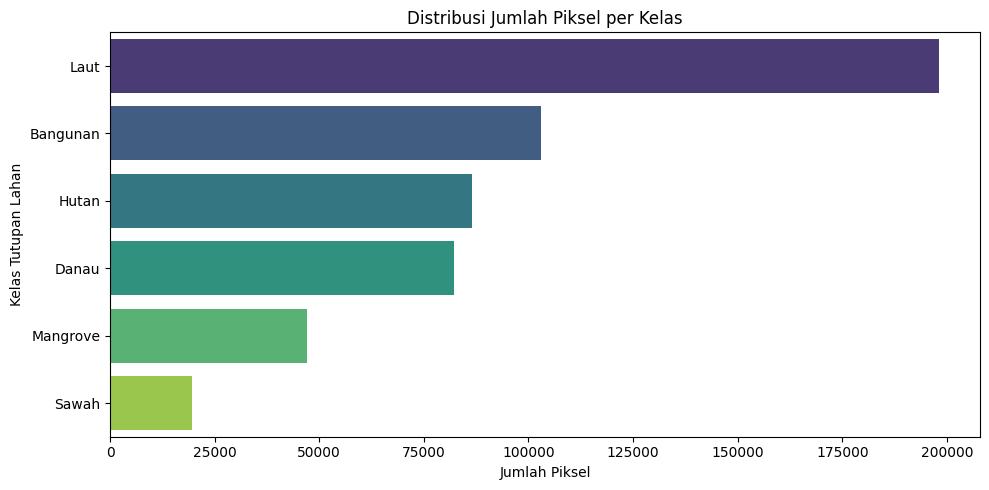

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.countplot(
    y='label_teks',
    data=df,
    palette='viridis',
    order=df['label_teks'].value_counts().index,
)
plt.title('Distribusi Jumlah Piksel per Kelas')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Tutupan Lahan')
plt.tight_layout()
plt.show()

C:\Users\NEC VH-3\AppData\Local\Temp\ipykernel_18856\2307992543.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')


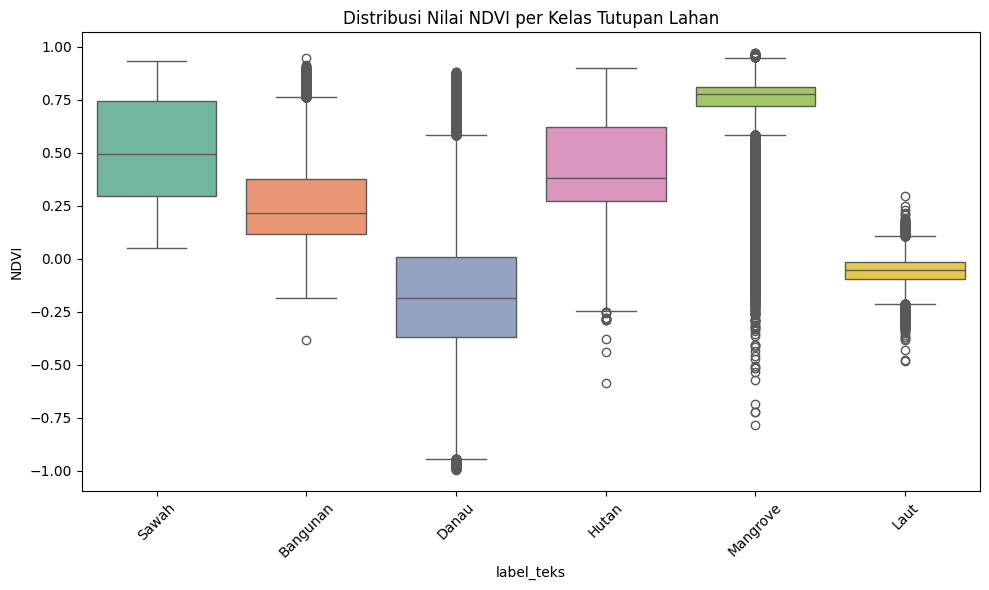

In [3]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')
plt.title('Distribusi Nilai NDVI per Kelas Tutupan Lahan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
# Ringkasan distribusi kelas
kelas_summary = df['label_teks'].value_counts().reset_index()
kelas_summary.columns = ['kelas', 'jumlah_piksel']
kelas_summary

,kelas,jumlah_piksel
0,Laut,198000
1,Bangunan,103017
2,Hutan,86390
3,Danau,82250
4,Mangrove,46984
5,Sawah,19512


In [5]:
# Korelasi antar fitur numerik
feat = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']
correlation = df[feat].corr()
correlation

,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI
B02,1.000000,0.933868,0.879638,0.225569,0.523836,-0.117206,-0.016137,-0.149345,0.287941
B03,0.933868,1.000000,0.916346,0.463958,0.657621,0.097529,-0.213869,-0.295778,0.142146
B04,0.879638,0.916346,1.000000,0.452318,0.779821,0.087720,-0.273777,-0.433979,0.310048
B08,0.225569,0.463958,0.452318,1.000000,0.777906,0.874743,-0.902486,-0.817763,-0.363324
B11,0.523836,0.657621,0.779821,0.777906,1.000000,0.536791,-0.686645,-0.835660,0.201158
NDVI,-0.117206,0.097529,0.087720,0.874743,0.536791,1.000000,-0.965653,-0.802275,-0.565116
NDWI,-0.016137,-0.213869,-0.273777,-0.902486,-0.686645,-0.965653,1.000000,0.909772,0.404425
MNDWI,-0.149345,-0.295778,-0.433979,-0.817763,-0.835660,-0.802275,0.909772,1.000000,-0.004702
NDBI,0.287941,0.142146,0.310048,-0.363324,0.201158,-0.565116,0.404425,-0.004702,1.000000


In [6]:
# Statistik ringkas per kelas
summary = df.groupby('label_teks')[['NDVI', 'NDWI', 'MNDWI', 'NDBI']].describe()
summary

NDVI                                                    \
               count      mean       std       min       25%       50%   
label_teks                                                               
Bangunan    103017.0  0.267716  0.194219 -0.384461  0.119355  0.216110   
Danau        82250.0 -0.151929  0.339944 -0.995516 -0.371131 -0.184475   
Hutan        86390.0  0.445488  0.208737 -0.587549  0.274079  0.382974   
Laut        198000.0 -0.055156  0.061069 -0.484311 -0.093897 -0.050922   
Mangrove     46984.0  0.719446  0.188740 -0.782716  0.721143  0.778089   
Sawah        19512.0  0.510474  0.226814  0.050611  0.298381  0.492283   

                                    NDWI            ...     MNDWI            \
                 75%       max     count      mean  ...       75%       max   
label_teks                                          ...                       
Bangunan    0.377112  0.946582  103017.0 -0.318679  ... -0.329606  0.529332   
Danau       0.010855  0.882682   82250.0  0.281002  ...  0.530429  0.887541   
Hutan       0.621696  0.901826   86390.0 -0.466136  ... -0.456457  0.797608   
Laut       -0.013018  0.298701  198000.0  0.141295  ...  0.197952  0.633721   
Mangrove    0.812682  0.970255   46984.0 -0.602967  ... -0.301294  0.839370   
Sawah       0.744959  0.934845   19512.0 -0.480865  ... -0.316354  0.236808   

                NDBI                                                    \
               count      mean       std       min       25%       50%   
label_teks                                                               
Bangunan    103017.0  0.079280  0.142796 -0.493011  0.004802  0.109182   
Danau        82250.0  0.031555  0.260376 -0.825148 -0.136293 -0.001818   
Hutan        86390.0  0.027790  0.185822 -0.804603 -0.111031  0.076783   
Laut        198000.0  0.015982  0.086204 -0.344643 -0.040140  0.025229   
Mangrove     46984.0 -0.359675  0.114160 -0.784127 -0.423187 -0.378034   
Sawah        19512.0 -0.148936  0.164835 -0.490683 -0.286686 -0.162072   

                                
                 75%       max  
label_teks                      
Bangunan    0.181191  0.698522  
Danau       0.155516  0.995829  
Hutan       0.171599  0.525428  
Laut        0.077640  0.532294  
Mangrove   -0.325045  0.776081  
Sawah      -0.018390  0.303045  

[6 rows x 32 columns]

In [7]:
# Cek missing value
missing = df.isnull().sum()
missing[missing > 0]

Series([], dtype: int64)

C:\Users\NEC VH-3\AppData\Local\Temp\ipykernel_18856\2405713363.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='label_teks', y='NDVI', data=df, palette='Set2')


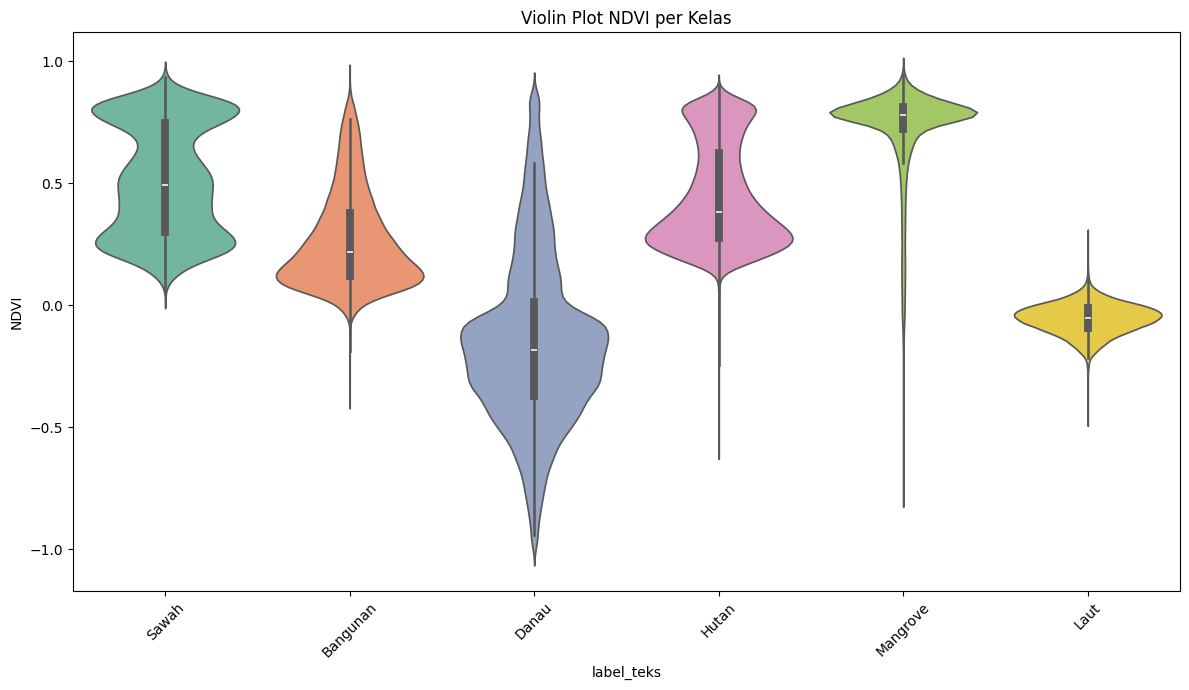

In [8]:
# Visualisasi distribusi nilai NDVI per kelas secara lebih detail
plt.figure(figsize=(12, 7))
sns.violinplot(x='label_teks', y='NDVI', data=df, palette='Set2')
plt.title('Violin Plot NDVI per Kelas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\NEC VH-3\AppData\Local\Temp\ipykernel_18856\737421560.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='label_teks', y='NDBI', data=df, palette='viridis')


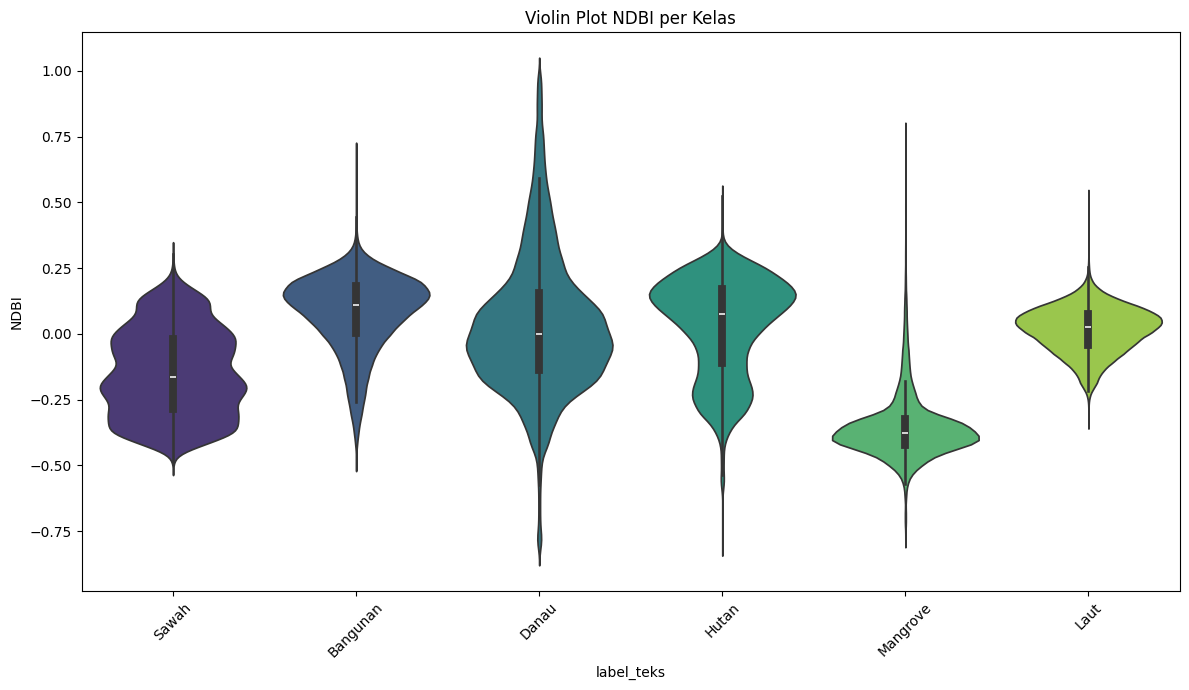

In [9]:
# Visualisasi distribusi nilai NDBI per kelas
plt.figure(figsize=(12, 7))
sns.violinplot(x='label_teks', y='NDBI', data=df, palette='viridis')
plt.title('Violin Plot NDBI per Kelas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# Nilai rata-rata per kelas
mean_by_class = df.groupby('label_teks')[feat].mean().round(4)
mean_by_class

,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI
label_teks,,,,,,,,,
Bangunan,1007.2320,1208.2615,1360.7817,2323.0796,2716.9222,0.2677,-0.3187,-0.3933,0.0793
Danau,702.5105,906.8918,692.4726,801.6642,753.6434,-0.1519,0.2810,0.2656,0.0316
Hutan,692.3836,898.1512,958.7006,2527.7692,2688.8544,0.4455,-0.4661,-0.4987,0.0278
Laut,501.1198,465.7547,403.9414,370.5519,399.5413,-0.0552,0.1413,0.1227,0.0160
Mangrove,348.6313,674.2843,434.1942,2886.2747,1342.4000,0.7194,-0.6030,-0.3231,-0.3597
Sawah,625.3190,870.0007,806.1807,2703.4999,1956.8352,0.5105,-0.4809,-0.3698,-0.1489


In [11]:
# Kelas dengan jumlah piksel terbesar dan terkecil
class_counts = df['label_teks'].value_counts()
print(class_counts)
print(f"Kelas mayoritas: {class_counts.idxmax()} ({class_counts.max()})")
print(f"Kelas minoritas: {class_counts.idxmin()} ({class_counts.min()})")

label_teks
Laut        198000
Bangunan    103017
Hutan        86390
Danau        82250
Mangrove     46984
Sawah        19512
Name: count, dtype: int64
Kelas mayoritas: Laut (198000)
Kelas minoritas: Sawah (19512)


In [12]:
# Persentase distribusi kelas
class_pct = (df['label_teks'].value_counts() / len(df) * 100).round(2)
class_pct

label_teks
Laut        36.93
Bangunan    19.21
Hutan       16.11
Danau       15.34
Mangrove     8.76
Sawah        3.64
Name: count, dtype: float64